# Лабораторная работа №1. Регрессионный анализ

**Студент:** Васютинский Вадим Александрович
**Вариант:** 8 (`lab1-08.csv`)

**Цель:** научиться применять модели линейной регрессии библиотеки scikit-learn к набору эмпирических данных.

**Результат:** эмпирическая формула зависимости $y(x)$.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
DATA_PATH = Path('..') / '..' / 'tasks' / 'lab1' / 'dataset' / 'lab1-08.csv'

## 1. Загрузка данных

In [2]:
data = pd.read_csv(DATA_PATH, header=None, names=['x', 'y'])
data.head()

,x,y
0,7.393939,-4.832168
1,-2.595960,21.935301
2,-1.030303,8.319461
3,7.454545,-3.898417
4,-2.292929,16.866421


In [3]:
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       200 non-null    float64
 1   y       200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


,x,y
count,200.000000,200.000000
mean,2.250000,3.245133
std,3.194769,7.961822
min,-3.000000,-6.088947
25%,-0.487374,-2.308487
50%,2.000000,0.580878
75%,4.984848,6.787182
max,8.000000,25.796033


Файл содержит 200 наблюдений и два числовых столбца без пропусков: признак $x \in [-3, 8]$ и целевую переменную $y$.

## 2. Визуализация исходных данных

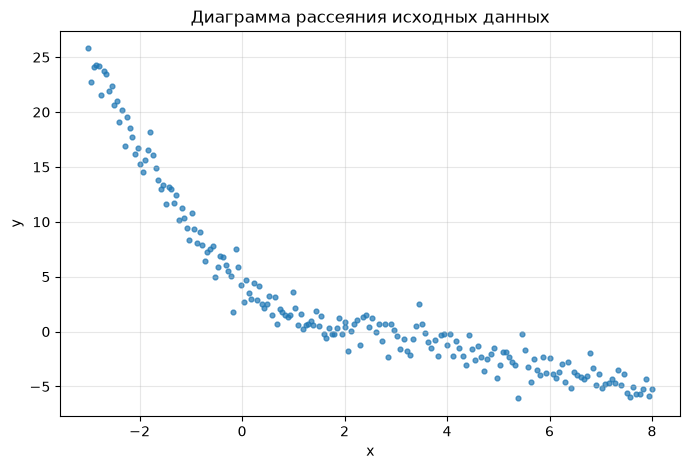

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(data['x'], data['y'], s=12, alpha=0.7)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Диаграмма рассеяния исходных данных')
ax.grid(alpha=0.3)
plt.show()

Зависимость явно нелинейная: при $x < 1$ значения $y$ резко убывают (по форме похоже на экспоненту $e^{-kx}$),
а при $x > 1$ убывание становится медленным и почти линейным, без выхода на горизонтальную асимптоту.
Поэтому кроме обычной прямой рассмотрим две модели, линейные по параметрам:

1. полиномиальную регрессию $y = \sum_{i=0}^{n} w_i x^i$;
2. регрессию на признаках $e^{-kx}$ и $x$: $y = a e^{-kx} + b x + c$.

Обе модели обучаются с помощью `LinearRegression`, нелинейность вносится через преобразование признаков.

## 3. Разбиение на обучающую и тестовую выборки

In [5]:
X = data[['x']]
y = data['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f'Обучающая выборка: {len(X_train)}, тестовая: {len(X_test)}')

Обучающая выборка: 160, тестовая: 40


Тестовая выборка (20 %) используется только для итоговой оценки.
Гиперпараметры (степень полинома, коэффициент $k$) подбираются кросс-валидацией на обучающей выборке.

## 4–5. Выбор и обучение моделей

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def evaluate(model, name):
    """Считает метрики модели на обучающей и тестовой выборках."""
    rows = []
    for split, X_part, y_part in [('train', X_train, y_train), ('test', X_test, y_test)]:
        pred = model.predict(X_part)
        rows.append({
            'model': name,
            'split': split,
            'MSE': mean_squared_error(y_part, pred),
            'MAE': mean_absolute_error(y_part, pred),
            'R2': r2_score(y_part, pred),
        })
    return rows

### 5.1. Базовая модель: простая линейная регрессия $y = w_1 x + w_0$

In [7]:
linear = LinearRegression().fit(X_train, y_train)
print(f'y = {linear.coef_[0]:.4f} * x + {linear.intercept_:.4f}')

y = -2.1636 * x + 8.0350
